# Electric field vectors at an interface

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch02/ch02-05.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## Import libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

In [ ]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

## Initialize variables

![Electric field reflecting and refracting at an interface. Components parallel and perpendicular to the plane of incidence are shown.](https://raw.githubusercontent.com/durstme/textbook-biomedicalimaging-notebooks/main/figures/ch02/figure-ch02-interfacevectors1.png)

Let us choose the x-y plane to be the plane of incidence, with the y-direction normal to the interface and the z-axis pointing out of the page (the interface is the x-z plane). 

![Electric field components corresponding to angles of incidence, reflection, and transmission.](https://raw.githubusercontent.com/durstme/textbook-biomedicalimaging-notebooks/main/figures/ch02/figure-ch02-interfacevectors2.png)

The propagation vectors for each wave can then be written as: 
$$\begin{split}
\vec{k}_i&=k_i \left( \sin \left( \theta_i \right) \hat{i}- \cos \left( \theta_i \right) \hat{j} \right) \\
\vec{k}_r&=k_r \left( \sin \left( \theta_r \right) \hat{i}+ \cos \left( \theta_r \right) \hat{j} \right) \\
\vec{k}_t&=k_t \left( \sin \left( \theta_t \right) \hat{i}- \cos \left( \theta_t \right) \hat{j} \right)
\end{split}$$
The electric field will be perpendicular to the propagation vector. It is useful to break the electric field vector components into parts parallel and perpendicular to the **plane of incidence**. In our coordinate system, the z-axis is perpendicular, and x-y are parallel, which means that the perpendicular component of the electric field must be in the $\hat{k}$ direction.  We can find the direction of the electric fields both from the figure above and from the cross-product:

$$\begin{split}
\vec{E}_{0i} &= \vec{E}_{i}^{\parallel} + \vec{E}_{i}^{\perp} \\
\vec{E}_{i}^{\perp} &= E_{i}^{\perp} \hat{k} \\
\vec{E}_{i}^{\parallel} &= E_{i}^{\parallel} \left(\hat{k} \times \vec{k}_{i}\right) = E_{i}^{\parallel} \left( \sin \left( \theta_i \right) \hat{k} \times \hat{i}- \cos \left( \theta_i \right) \hat{k}\times \hat{j} \right)\\
&=  E_{i}^{\parallel} \left( \cos \left( \theta_i \right) \hat{i} + \sin \left( \theta_i \right) \hat{j}  \right) \\
\\
\vec{E}_{0r} &= \vec{E}_{r}^{\parallel} + \vec{E}_{r}^{\perp} \\
\vec{E}_{r}^{\perp} &= E_{r}^{\perp} \hat{k} \\
\vec{E}_{r}^{\parallel} &= E_{r}^{\parallel} \left(\hat{k} \times \vec{k}_{i}\right) = E_{r}^{\parallel} \left( \sin \left( \theta_r \right) \hat{k} \times \hat{i}+ \cos \left( \theta_r \right) \hat{k}\times \hat{j} \right)\\
&=  E_{r}^{\parallel} \left(- \cos \left( \theta_r \right) \hat{i} + \sin \left( \theta_r \right) \hat{j}  \right) \\
\\
\vec{E}_{0t} &= \vec{E}_{t}^{\parallel} + \vec{E}_{t}^{\perp} \\
\vec{E}_{t}^{\perp} &= E_{t}^{\perp} \hat{k} \\
\vec{E}_{t}^{\parallel} &= E_{t}^{\parallel} \left(\hat{k} \times \vec{k}_{i}\right) = E_{t}^{\parallel} \left( \sin \left( \theta_t \right) \hat{k} \times \hat{i}- \cos \left( \theta_t \right) \hat{k}\times \hat{j} \right)\\
&=  E_{t}^{\parallel} \left( \cos \left( \theta_t \right) \hat{i} + \sin \left( \theta_t \right) \hat{j}  \right) \\
\end{split}$$

Next, we break the electric field vector components into parts parallel and perpendicular to the **plane of incidence**. In our coordinate system, the z-axis is perpendicular, and x-y are parallel:
$$\begin{split}
\vec{E}_i &= \vec{E}_{0i} e^{i \left( \vec{k}_i \cdot \vec{r}-\omega_i t \right)} = \left[ E_i^{\parallel} \left( \cos \left( \theta_i \right) \hat{i}+\sin \left( \theta_i \right) \hat{j} \right)+E_i^{\perp} \hat{k} \right] e^{i \left[ k_i \left( x \sin \left(\theta_i \right)-y \cos \left( \theta_i \right) \right)-\omega_i t \right]}  \\
\vec{E}_r &= \vec{E}_{0r} e^{i \left( \vec{k}_r \cdot \vec{r}-\omega_i t \right)} = \left[ E_r^{\parallel} \left( -\cos \left( \theta_r \right) \hat{i}+\sin \left( \theta_r \right) \hat{j} \right)+E_r^{\perp} \hat{k} \right] e^{i \left[ k_r \left( x \sin \left(\theta_r \right)+y \cos \left( \theta_r \right) \right)-\omega_r t \right]}  \\
\vec{E}_t &= \vec{E}_{0t} e^{i \left( \vec{k}_t \cdot \vec{r}-\omega_i t \right)} = \left[ E_t^{\parallel} \left( \cos \left( \theta_t \right) \hat{i}+\sin \left( \theta_t \right) \hat{j} \right)+E_t^{\perp} \hat{k} \right] e^{i \left[ k_t \left( x \sin \left(\theta_t \right)-y \cos \left( \theta_t \right) \right)-\omega_t t \right]}
\end{split}$$
where the directions of the electric fields are chosen to be perpendicular to the propagation vectors.

The magnitudes of the electric field components are $E_{\parallel}$ and $E_{\perp}$ can be obtained relative to the incident magnetic field $E_i$ using the Fresnel equations:
$$\begin{split}
r_{\perp}&= \frac{E_r^{\perp}}{E_i^{\perp}} = \frac{n_i \cos \left( \theta_i \right)-n_t \cos \left( \theta_t \right)}{n_i \cos \left( \theta_i \right)+n_t \cos \left( \theta_t \right)}\\
t_{\perp}&= \frac{E_t^{\perp}}{E_i^{\perp}} = \frac{2 n_i \cos \left( \theta_i \right)}{n_i \cos \left( \theta_i \right)+n_t \cos \left( \theta_t \right)} \\
r_{\parallel}&= \frac{E_r^{\parallel}}{E_i^{\parallel}} = \frac{n_t \cos \left( \theta_i \right)-n_i \cos \left( \theta_t \right)}{n_i \cos \left( \theta_t \right)+n_t \cos \left( \theta_i \right)} \\
t_{\parallel}&= \frac{E_r^{\parallel}}{E_i^{\parallel}} = \frac{2 n_i \cos \left( \theta_i \right)}{n_i \cos \left( \theta_t \right)+n_t \cos \left( \theta_i \right)}
\end{split}$$
Putting these together, we can isolate the parallel and perpendicular components of the electric field:
$$\begin{split}
E_r^{\parallel}&= r_{\parallel} E_i \\
E_r^{\perp}&= r_{\perp} E_i \\
E_t^{\parallel}&= t_{\parallel} E_i \\
E_t^{\perp}&= t_{\perp} E_i
\end{split}$$


In [2]:
# Constants
ni = 1.00
nt = 1.50
omega0 = 1
phi0 = 0
k_mag0 = 4
t0 = 0
numpoints1 = 256
numangles1 = 30

theta_i_deg1 = np.linspace(0,90,numangles1) # Incident angles in degrees
theta_i1 = np.radians(theta_i_deg1) # Incident angle in radians
theta_t1 = np.arcsin(ni / nt * np.sin(theta_i1)) # Law of Refraction to solve for transmitted angle

# test for angles above critical angle (leading to NaN values)
critical_angle1 = np.arcsin(nt/ni) if ni > nt else np.pi/2
test_critical1 = theta_i1 > critical_angle1
theta_t1[test_critical1] = np.pi/2  # set transmitted angle to NaN for angles above critical angle

# Wave vector directions
ki1_dir = np.array([np.sin(theta_i1), -np.cos(theta_i1),np.zeros_like(theta_i1)]).T
kr1_dir = np.array([np.sin(theta_i1), np.cos(theta_i1),np.zeros_like(theta_i1)]).T
kt1_dir = np.array([np.sin(theta_t1), -np.cos(theta_t1),np.zeros_like(theta_i1)]).T

# Wave vectors
ki1 = ni * k_mag0 * ki1_dir
kr1 = ni * k_mag0 * kr1_dir
kt1 = nt * k_mag0 * kt1_dir

# Fresnel coefficients
tperp1 = 2 * ni * np.cos(theta_i1) / (ni * np.cos(theta_i1) + nt * np.cos(theta_t1))
rperp1 = (ni * np.cos(theta_i1) - nt * np.cos(theta_t1)) / (ni * np.cos(theta_i1) + nt * np.cos(theta_t1))

tpar1 = 2 * ni * np.cos(theta_i1) / (ni * np.cos(theta_t1) + nt * np.cos(theta_i1))
rpar1 = (nt * np.cos(theta_i1) - ni * np.cos(theta_t1)) / (ni * np.cos(theta_t1) + nt * np.cos(theta_i1))

# Set coefficients to zero during TIR to handle the case correctly
tperp1[test_critical1] = 0
rperp1[test_critical1] = 1 
tpar1[test_critical1] = 0
rpar1[test_critical1] = 1

# Electric field directions
Ei1perp_dir = np.tile(np.array([0,0,1]),(numangles1,1))
Ei1par_dir = np.cross(Ei1perp_dir,ki1_dir)  # cross product to get direction perpendicular to ki and z
Ei1par_dir /= np.linalg.norm(Ei1par_dir, axis=1)[:, None]  # Normalize

Er1perp_dir = np.tile(np.array([0,0,1]),(numangles1,1))
Er1par_dir = np.cross(Er1perp_dir,kr1_dir)  # cross product to get direction perpendicular to kr and z
Er1par_dir /= np.linalg.norm(Er1par_dir, axis=1)[:, None]  # Normalize

Et1perp_dir = np.tile(np.array([0,0,1]),(numangles1,1))
Et1par_dir = np.cross(Et1perp_dir,kt1_dir)  # cross product to get direction perpendicular to kt and z
Et1par_dir /= np.linalg.norm(Et1par_dir, axis=1)[:, None]  # Normalize

# Electric field magnitudes
Ei1perp_mag = np.ones(numangles1)
Ei1par_mag = np.ones(numangles1)

Er1perp_mag = rperp1 * Ei1perp_mag
Er1par_mag = rpar1 * Ei1par_mag

Et1perp_mag = tperp1 * Ei1perp_mag
Et1par_mag = tpar1 * Ei1par_mag

# Electric field vectors
Ei1perp = Ei1perp_mag[:, np.newaxis] * Ei1perp_dir
Ei1par = Ei1par_mag[:, np.newaxis] * Ei1par_dir

Er1perp = Er1perp_mag[:, np.newaxis] * Er1perp_dir
Er1par = Er1par_mag[:, np.newaxis] * Er1par_dir

Et1perp = Et1perp_mag[:, np.newaxis] * Et1perp_dir
Et1par = Et1par_mag[:, np.newaxis] * Et1par_dir

# Positions of points to obey Laws of Reflection and Refraction
point1i = np.array([-ki1[:,0], -ki1[:,1], np.zeros_like(ki1[:,0])]).T
point1r = np.array([kr1[:,0], kr1[:,1], np.zeros_like(kr1[:,0])]).T
point1t = np.array([kt1[:,0], kt1[:,1], np.zeros_like(kt1[:,0])]).T/nt

# Positions of tips of each vector
ki1_line = point1i + ki1_dir
kr1_line = point1r + kr1_dir
kt1_line = point1t + kt1_dir

Ei1perp_line = point1i + Ei1perp
Ei1par_line = point1i + Ei1par

Er1perp_line = point1r + Er1perp
Er1par_line = point1r + Er1par

Et1perp_line = point1t + Et1perp
Et1par_line = point1t + Et1par


## Plot with `matplotlib`

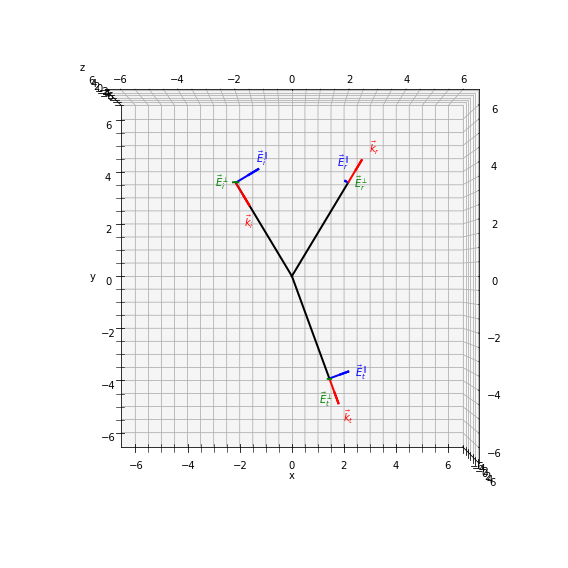

In [3]:
# Set up figure and axis
fig1 = plt.figure(figsize=(10, 8))
ax1 = fig1.add_subplot(111, projection='3d')

index1 = 10
# Plot lines
plotray1i = ax1.plot(np.array([-ki1[index1,0],0]), np.array([-ki1[index1,1],0]), np.array([0,0]), color='black', label='incident ray', linewidth=2)
plotray1r = ax1.plot(np.array([0,kr1[index1,0]]), np.array([0,kr1[index1,1]]), np.array([0,0]), color='black', label='reflected ray', linewidth=2)
plotray1t = ax1.plot(np.array([0,kt1[index1,0]/nt]), np.array([0,kt1[index1,1]/nt]), np.array([0,0]), color='black', label='transmitted ray', linewidth=2)

# Plot arrows
plotki1 = ax1.quiver(point1i[index1,0], point1i[index1,1], point1i[index1,2], ki1_dir[index1,0], ki1_dir[index1,1], ki1_dir[index1,2], color='red', label='k incident', linewidth=2, arrow_length_ratio=0.5)
plotkr1 = ax1.quiver(point1r[index1,0], point1r[index1,1], point1r[index1,2], kr1_dir[index1,0], kr1_dir[index1,1], kr1_dir[index1,2], color='red', label='k reflected', linewidth=2, arrow_length_ratio=0.5)
plotkt1 = ax1.quiver(point1t[index1,0], point1t[index1,1], point1t[index1,2], kt1_dir[index1,0], kt1_dir[index1,1], kt1_dir[index1,2], color='red', label='k transmitted', linewidth=2, arrow_length_ratio=0.5)

plotEi1par = ax1.quiver(point1i[index1,0], point1i[index1,1], point1i[index1,2], Ei1par[index1,0], Ei1par[index1,1], Ei1par[index1,2], color='blue', label='E incident - parallel', linewidth=2, arrow_length_ratio=0.5)
plotEr1par = ax1.quiver(point1r[index1,0], point1r[index1,1], point1r[index1,2], Er1par[index1,0], Er1par[index1,1], Er1par[index1,2], color='blue', label='E reflected - parallel', linewidth=2, arrow_length_ratio=0.5)
plotEt1par = ax1.quiver(point1t[index1,0], point1t[index1,1], point1t[index1,2], Et1par[index1,0], Et1par[index1,1], Et1par[index1,2], color='blue', label='E transmitted - parallel', linewidth=2, arrow_length_ratio=0.5)

plotEi1perp = ax1.quiver(point1i[index1,0], point1i[index1,1], point1i[index1,2], Ei1perp[index1,0], Ei1perp[index1,1], Ei1perp[index1,2], color='green', label='E incident - perpendicular', linewidth=2, arrow_length_ratio=0.5)
plotEr1perp = ax1.quiver(point1r[index1,0], point1r[index1,1], point1r[index1,2], Er1perp[index1,0], Er1perp[index1,1], Er1perp[index1,2], color='green', label='E reflected - perpendicular', linewidth=2, arrow_length_ratio=0.5)
plotEt1perp = ax1.quiver(point1t[index1,0], point1t[index1,1], point1t[index1,2], Et1perp[index1,0], Et1perp[index1,1], Et1perp[index1,2], color='green', label='E transmitted - perpendicular', linewidth=2, arrow_length_ratio=0.5)

# Calculate the label position (at the tip of the arrow with a small offset)
label_ki1 = ki1_line[index1,:]*0.9
label_kr1 = kr1_line[index1,:]*1.1
label_kt1 = kt1_line[index1,:]*1.1

label_Ei1par = Ei1par_line[index1,:]*1.1
label_Er1par = Er1par_line[index1,:]*1.1
label_Et1par = Et1par_line[index1,:]*1.1

label_Ei1perp = Ei1perp_line[index1,:]*1.1
label_Er1perp = Er1perp_line[index1,:]*1.1
label_Et1perp = Et1perp_line[index1,:]*1.1

    
# Add the text label
ax1.text(label_ki1[0], label_ki1[1], label_ki1[2], r'$\vec{k}_i$', color='red', ha = 'right', va = 'top')
ax1.text(label_kr1[0], label_kr1[1], label_kr1[2], r'$\vec{k}_r$', color='red', ha = 'left', va = 'center')
ax1.text(label_kt1[0], label_kt1[1], label_kt1[2], r'$\vec{k}_t$', color='red', ha = 'left', va = 'center')

ax1.text(label_Ei1par[0], label_Ei1par[1], label_Ei1par[2], r'$\vec{E}_i^{\parallel}$', color='blue', ha = 'left', va = 'center')
ax1.text(label_Er1par[0], label_Er1par[1], label_Er1par[2], r'$\vec{E}_r^{\parallel}$', color='blue', ha = 'right', va = 'bottom')
ax1.text(label_Et1par[0], label_Et1par[1], label_Et1par[2], r'$\vec{E}_t^{\parallel}$', color='blue', ha = 'left', va = 'bottom')

ax1.text(label_Ei1perp[0], label_Ei1perp[1], label_Ei1perp[2], r'$\vec{E}_i^{\perp}$', color='green', ha = 'right', va = 'top')
ax1.text(label_Er1perp[0], label_Er1perp[1], label_Er1perp[2], r'$\vec{E}_r^{\perp}$', color='green', ha = 'left', va = 'top')
ax1.text(label_Et1perp[0], label_Et1perp[1], label_Et1perp[2], r'$\vec{E}_t^{\perp}$', color='green', ha = 'right', va = 'top')

# Set labels and title
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_zlabel('z')
# ax1.set_title('3D Plane Wave with Multiple Phase Surfaces')

# set the tick mark parameters
ax1.minorticks_on()
ax1.tick_params(which='both',direction="in",width=1)
ax1.tick_params(which='major',length=7)
ax1.tick_params(which='minor',length=3.5)
ax1.xaxis.set_ticks_position('both')
ax1.yaxis.set_ticks_position('both')
ax1.zaxis.set_ticks_position('both')

# set axes limits
ax1.set_xlim(-2*np.pi, 2*np.pi)
ax1.set_ylim(-2*np.pi, 2*np.pi)
ax1.set_zlim(-2*np.pi, 2*np.pi)


ax1.view_init(elev=90, azim=-90)

# show the plot
plt.tight_layout()
plt.show()


## Create `plotly` plot with slider

In [ ]:

# Create frames for slider
frames = []
for i in range(numangles1):
    data = []

    # Rays
    data.append(go.Scatter3d(x=[-ki1[i, 0], 0], y=[-ki1[i, 1], 0], z=[0, 0], mode='lines', line=dict(color='black', width=6), name='incident ray'))
    data.append(go.Scatter3d(x=[0, kr1[i, 0]], y=[0, kr1[i, 1]], z=[0, 0], mode='lines', line=dict(color='black', width=6), name='reflected ray'))
    data.append(go.Scatter3d(x=[0, kt1[i, 0]/nt], y=[0, kt1[i, 1]/nt], z=[0, 0], mode='lines', line=dict(color='black', width=6), name='transmitted ray'))

    # Line parts of arrows
    data += [
        go.Scatter3d(x=[point1i[i,0], ki1_line[i,0]],y=[point1i[i,1], ki1_line[i,1]],z=[point1i[i,2], ki1_line[i,2]], mode='lines', line=dict(color='red', width=6), name='k incident'),
        go.Scatter3d(x=[point1r[i,0], kr1_line[i,0]],y=[point1r[i,1], kr1_line[i,1]],z=[point1r[i,2], kr1_line[i,2]], mode='lines', line=dict(color='red', width=6), name='k reflected'),
        go.Scatter3d(x=[point1t[i,0], kt1_line[i,0]],y=[point1t[i,1], kt1_line[i,1]],z=[point1t[i,2], kt1_line[i,2]], mode='lines', line=dict(color='red', width=6), name='k transmitted'),

        go.Scatter3d(x=[point1i[i,0], Ei1par_line[i,0]],y=[point1i[i,1], Ei1par_line[i,1]],z=[point1i[i,2], Ei1par_line[i,2]], mode='lines', line=dict(color='blue', width=6), name='E incident - parallel'),
        go.Scatter3d(x=[point1r[i,0], Er1par_line[i,0]],y=[point1r[i,1], Er1par_line[i,1]],z=[point1r[i,2], Er1par_line[i,2]], mode='lines', line=dict(color='blue', width=6), name='E reflected - parallel'),
        go.Scatter3d(x=[point1t[i,0], Et1par_line[i,0]],y=[point1t[i,1], Et1par_line[i,1]],z=[point1t[i,2], Et1par_line[i,2]], mode='lines', line=dict(color='blue', width=6), name='E transmitted - parallel'),

        go.Scatter3d(x=[point1i[i,0], Ei1perp_line[i,0]],y=[point1i[i,1], Ei1perp_line[i,1]],z=[point1i[i,2], Ei1perp_line[i,2]], mode='lines', line=dict(color='green', width=6), name='E incident - perpendicular'),
        go.Scatter3d(x=[point1r[i,0], Er1perp_line[i,0]],y=[point1r[i,1], Er1perp_line[i,1]],z=[point1r[i,2], Er1perp_line[i,2]], mode='lines', line=dict(color='green', width=6), name='E reflected - perpendicular'),
        go.Scatter3d(x=[point1t[i,0], Et1perp_line[i,0]],y=[point1t[i,1], Et1perp_line[i,1]],z=[point1t[i,2], Et1perp_line[i,2]], mode='lines', line=dict(color='green', width=6), name='E transmitted - perpendicular')
    ]

    # Arrow tips
    data += [
        go.Cone(x=[ki1_line[i,0]], y=[ki1_line[i,1]], z=[ki1_line[i,2]],u=[ki1_dir[i,0]], v=[ki1_dir[i,1]], w=[ki1_dir[i,2]], colorscale='Reds', sizemode='absolute', sizeref=1.0, showscale=False, name='E Field', anchor="tail"),
        go.Cone(x=[kr1_line[i,0]], y=[kr1_line[i,1]], z=[kr1_line[i,2]],u=[kr1_dir[i,0]], v=[kr1_dir[i,1]], w=[kr1_dir[i,2]], colorscale='Reds', sizemode='absolute', sizeref=1.0, showscale=False, name='E Field', anchor="tail"),
        go.Cone(x=[kt1_line[i,0]], y=[kt1_line[i,1]], z=[kt1_line[i,2]],u=[kt1_dir[i,0]], v=[kt1_dir[i,1]], w=[kt1_dir[i,2]], colorscale='Reds', sizemode='absolute', sizeref=1.0, showscale=False, name='E Field', anchor="tail"),

        go.Cone(x=[Ei1par_line[i,0]], y=[Ei1par_line[i,1]], z=[Ei1par_line[i,2]],u=[Ei1par[i,0]], v=[Ei1par[i,1]], w=[Ei1par[i,2]], colorscale='Blues', sizemode='scaled', sizeref=1.0, showscale=False, name='E Field', anchor="tail"),
        go.Cone(x=[Er1par_line[i,0]], y=[Er1par_line[i,1]], z=[Er1par_line[i,2]],u=[Er1par[i,0]], v=[Er1par[i,1]], w=[Er1par[i,2]], colorscale='Blues', sizemode='scaled', sizeref=1.0, showscale=False, name='E Field', anchor="tail"),
        go.Cone(x=[Et1par_line[i,0]], y=[Et1par_line[i,1]], z=[Et1par_line[i,2]],u=[Et1par[i,0]], v=[Et1par[i,1]], w=[Et1par[i,2]], colorscale='Blues', sizemode='scaled', sizeref=1.0, showscale=False, name='E Field', anchor="tail"),

        go.Cone(x=[Ei1perp_line[i,0]], y=[Ei1perp_line[i,1]], z=[Ei1perp_line[i,2]],u=[Ei1perp[i,0]], v=[Ei1perp[i,1]], w=[Ei1perp[i,2]], colorscale='Greens', sizemode='scaled', sizeref=1.0, showscale=False, name='E Field', anchor="tail"),
        go.Cone(x=[Er1perp_line[i,0]], y=[Er1perp_line[i,1]], z=[Er1perp_line[i,2]],u=[Er1perp[i,0]], v=[Er1perp[i,1]], w=[Er1perp[i,2]], colorscale='Greens', sizemode='scaled', sizeref=1.0, showscale=False, name='E Field', anchor="tail"),
        go.Cone(x=[Et1perp_line[i,0]], y=[Et1perp_line[i,1]], z=[Et1perp_line[i,2]],u=[Et1perp[i,0]], v=[Et1perp[i,1]], w=[Et1perp[i,2]], colorscale='Greens', sizemode='scaled', sizeref=1.0, showscale=False, name='E Field', anchor="tail")
    ]

    # Calculate the label position (at the tip of the arrow with a small offset)
    label_ki1_2 = ki1_line[i,:]*0.9
    label_kr1_2 = kr1_line[i,:]*1.1
    label_kt1_2 = kt1_line[i,:]*1.1

    label_Ei1par2 = Ei1par_line[i,:]*1.1
    label_Er1par2 = Er1par_line[i,:]*1.1
    label_Et1par2 = Et1par_line[i,:]*1.1

    label_Ei1perp2 = Ei1perp_line[i,:]*1.1
    label_Er1perp2 = Er1perp_line[i,:]*1.1
    label_Et1perp2 = Et1perp_line[i,:]*1.1

    # Add the text label
    data.append(go.Scatter3d(x=[label_ki1_2[0]], y=[label_ki1_2[1]], z=[label_ki1_2[2]], mode='text', text='kᵢ', textfont=dict(color='red', size=15), textposition="bottom center", showlegend=False))
    data.append(go.Scatter3d(x=[label_kr1_2[0]], y=[label_kr1_2[1]], z=[label_kr1_2[2]], mode='text', text='kᵣ', textfont=dict(color='red', size=15), textposition="middle right", showlegend=False))
    data.append(go.Scatter3d(x=[label_kt1_2[0]], y=[label_kt1_2[1]], z=[label_kt1_2[2]], mode='text', text='kₜ', textfont=dict(color='red', size=15), textposition="middle right", showlegend=False))
    
    data.append(go.Scatter3d(x=[label_Ei1par2[0]], y=[label_Ei1par2[1]], z=[label_Ei1par2[2]], mode='text', text='Eᵢ∥', textfont=dict(color='blue', size=15), textposition="top center", showlegend=False))
    data.append(go.Scatter3d(x=[label_Er1par2[0]], y=[label_Er1par2[1]], z=[label_Er1par2[2]], mode='text', text='Eᵣ∥', textfont=dict(color='blue', size=15), textposition="top center", showlegend=False))
    data.append(go.Scatter3d(x=[label_Et1par2[0]], y=[label_Et1par2[1]], z=[label_Et1par2[2]], mode='text', text='Eₜ∥', textfont=dict(color='blue', size=15), textposition="top center", showlegend=False))
    
    data.append(go.Scatter3d(x=[label_Ei1perp2[0]], y=[label_Ei1perp2[1]], z=[label_Ei1perp2[2]], mode='text', text='Eᵢ⊥', textfont=dict(color='green', size=15), textposition="middle left", showlegend=False))
    data.append(go.Scatter3d(x=[label_Er1perp2[0]], y=[label_Er1perp2[1]], z=[label_Er1perp2[2]], mode='text', text='Eᵣ⊥', textfont=dict(color='green', size=15), textposition="middle left", showlegend=False))
    data.append(go.Scatter3d(x=[label_Et1perp2[0]], y=[label_Et1perp2[1]], z=[label_Et1perp2[2]], mode='text', text='Eₜ⊥', textfont=dict(color='green', size=15), textposition="middle left", showlegend=False))
    
    frames.append(go.Frame(data=data, name=str(i)))

# Initial data
initial_data = frames[10].data

# Create figure
fig = go.Figure(
    data=initial_data,
    layout=go.Layout(
        width=700,
        height=int(700),
        font=dict(family='sans-serif', size=18),
        showlegend=False,
        plot_bgcolor='white',  # Removes the inner gray plot background
        paper_bgcolor='white', # Removes the outer figure background
        scene=dict(
            xaxis=dict(title='x', range=[-2*np.pi, 2*np.pi]),
            yaxis=dict(title='y', range=[-2*np.pi, 2*np.pi]),
            zaxis=dict(title='z', range=[-2*np.pi, 2*np.pi]),
            camera=dict(eye=dict(x=0, y=0, z=2), up=dict(x=0, y=1, z=0))
        ),
        updatemenus=[dict(
            type='buttons',
            buttons=[dict(label='Play', method='animate', args=[None]),
                     dict(label='Pause', method='animate', args=[[None], dict(frame=dict(duration=0, redraw=False), mode='immediate')])]
        )],
        sliders=[dict(
            steps=[dict(method='animate', args=[[str(k)], dict(mode='immediate', frame=dict(duration=0, redraw=True))], label=f'{theta_i_deg1[k]:.1f}°') for k in range(numangles1)],
            active=10,
            currentvalue=dict(prefix='Incident Angle: ')
        )]
    ),
    frames=frames
)

# --- Configure axis properties with new settings ---
fig.update_xaxes(
    # Sets the tick mark position
    ticks="inside",
    # Sets the tick mark width
    tickwidth=2,
    # Sets the major tick mark length
    ticklen=7,
    # Shows minor ticks and styles them
    minor=dict(ticks="inside", tickwidth=1, ticklen=3.5),
    showline=True, 
    linecolor='black', 
    linewidth=2,
    mirror=True  # Mirrors the axis line to create the top border
)

fig.update_yaxes(
    # Sets the tick mark position
    ticks="inside",
    # Sets the tick mark width
    tickwidth=2,
    # Sets the major tick mark length
    ticklen=7,
    # Shows minor ticks and styles them
    minor=dict(ticks="inside", tickwidth=1, ticklen=3.5),
    showline=True, 
    linecolor='black', 
    linewidth=2,
    mirror=True  # Mirrors the axis line to create the right border
    # scaleanchor='x',  # Constrain y-axis scaling to the x-axis
    # scaleratio=1      # Set the ratio of y units to x units to 1
)

fig.show()


### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-05_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch02/ch02-05.html) (direct link: [ch02-05_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch02/ch02-05_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.